**load data**

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split

import xgboost as xgb
import lightgbm as lgb
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (14,6)

# Load datasets
train = pd.read_csv("train.csv", parse_dates=['Date'])
test = pd.read_csv("test.csv", parse_dates=['Date'])
features = pd.read_csv("features.csv", parse_dates=['Date'])
stores = pd.read_csv("stores.csv")

# Merge features and store info
train = train.merge(features, on=['Store','Date','IsHoliday'], how='left')
train = train.merge(stores, on='Store', how='left')

**feature engineering**

In [5]:
df = train.copy()
df = df.sort_values(['Store','Dept','Date'])

# Time features
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['week'] = df['Date'].dt.isocalendar().week
df['dayofweek'] = df['Date'].dt.dayofweek

# Lag features
df['lag_1'] = df.groupby(['Store','Dept'])['Weekly_Sales'].shift(1)
df['lag_7'] = df.groupby(['Store','Dept'])['Weekly_Sales'].shift(7)

# Rolling averages
df['roll_mean_4'] = df.groupby(['Store','Dept'])['Weekly_Sales'].shift(1).rolling(window=4).mean()
df['roll_mean_12'] = df.groupby(['Store','Dept'])['Weekly_Sales'].shift(1).rolling(window=12).mean()

# Drop missing values
df.dropna(inplace=True)

**train & test split**

In [6]:
train_set = df[df['year'] < 2012]
test_set  = df[df['year'] == 2012]

features = ['Store','Dept','IsHoliday','Temperature','Fuel_Price','CPI','Unemployment',
            'year','month','week','dayofweek','lag_1','lag_7','roll_mean_4','roll_mean_12']

X_train, y_train = train_set[features], train_set['Weekly_Sales']
X_test, y_test   = test_set[features], test_set['Weekly_Sales']

***modeling & evaluation***

**linear regression**

In [7]:
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

print("Linear Regression RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))
print("Linear Regression MAE:", mean_absolute_error(y_test, y_pred_lr))

Linear Regression RMSE: 15724.385735252705
Linear Regression MAE: 13467.8753403101


**random forest**

In [8]:
rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print("Random Forest RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print("Random Forest MAE:", mean_absolute_error(y_test, y_pred_rf))

Random Forest RMSE: 11783.93911176142
Random Forest MAE: 3651.1966782881077


**XGBoost**

In [9]:
xgbr = xgb.XGBRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)
xgbr.fit(X_train, y_train)
y_pred_xgb = xgbr.predict(X_test)

print("XGBoost RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_xgb)))
print("XGBoost MAE:", mean_absolute_error(y_test, y_pred_xgb))

XGBoost RMSE: 15430.415656524841
XGBoost MAE: 3952.6563078002814


**LightGBM**

In [10]:
lgbm = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.1, max_depth=6, random_state=42)
lgbm.fit(X_train, y_train)
y_pred_lgb = lgbm.predict(X_test)

print("LightGBM RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lgb)))
print("LightGBM MAE:", mean_absolute_error(y_test, y_pred_lgb))

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001024 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1576
[LightGBM] [Info] Number of data points in the train set: 18594, number of used features: 13
[LightGBM] [Info] Start training from score 20975.343392
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best g

**model comparision**

In [14]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'XGBoost', 'LightGBM'],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_xgb)),
        np.sqrt(mean_squared_error(y_test, y_pred_lgb))
    ],
    'MAE': [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_xgb),
        mean_absolute_error(y_test, y_pred_lgb)
    ]
})

results.sort_values(by='RMSE')

,Model,RMSE,MAE
3,LightGBM,8683.617012,3539.304145
1,Random Forest,11783.939112,3651.196678
2,XGBoost,15430.415657,3952.656308
0,Linear Regression,15724.385735,13467.875340


**feature importance plot**

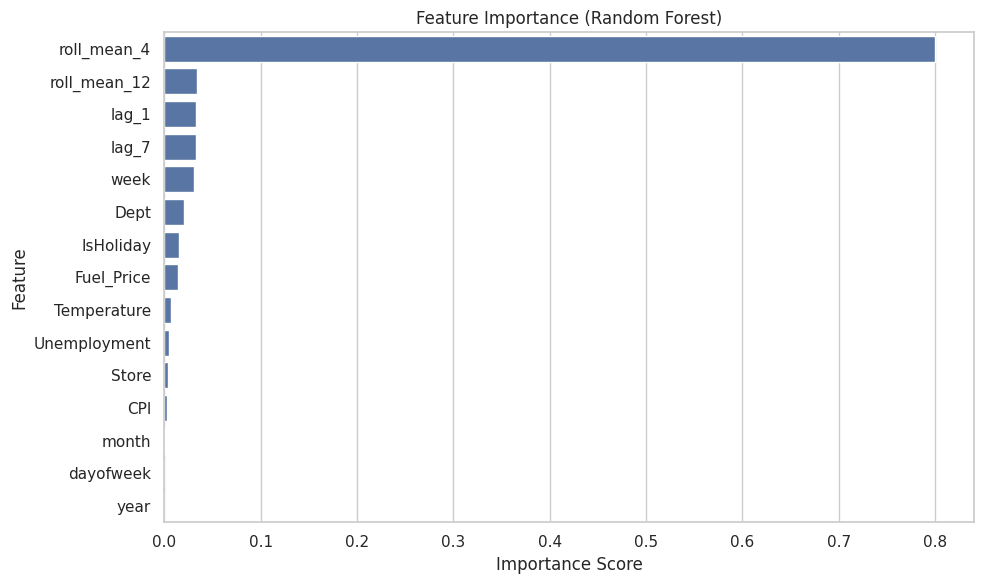

In [15]:
importances = rf.feature_importances_
feature_names = X_train.columns

feat_imp = pd.Series(importances, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10,6))
sns.barplot(x=feat_imp.values, y=feat_imp.index)
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

**visualization / prediction**

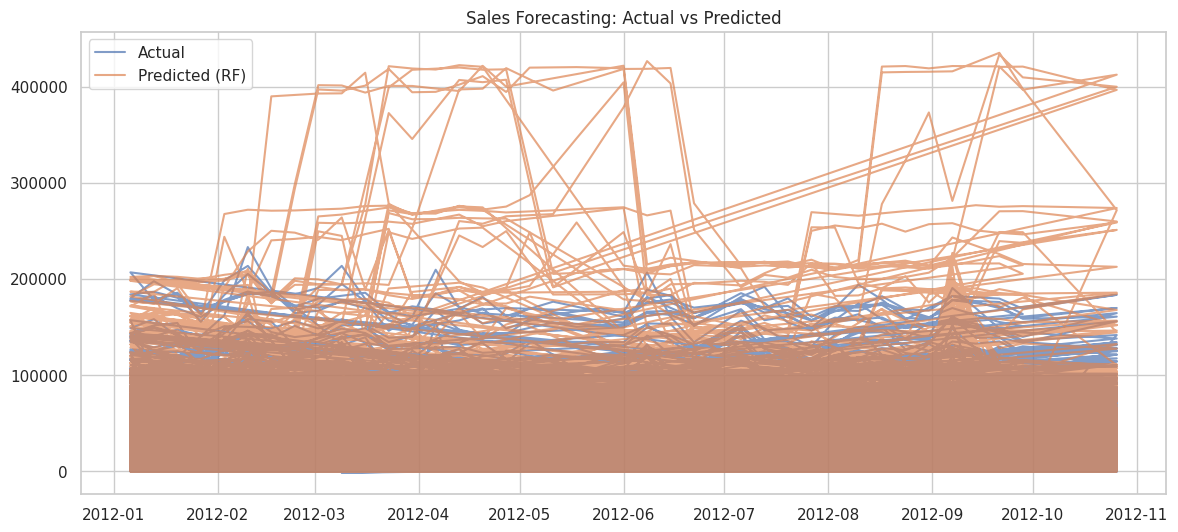

In [11]:
plt.plot(test_set['Date'], y_test.values, label="Actual", alpha=0.7)
plt.plot(test_set['Date'], y_pred_rf, label="Predicted (RF)", alpha=0.7)
plt.legend()
plt.title("Sales Forecasting: Actual vs Predicted")
plt.show()

**seasonal decomposition**

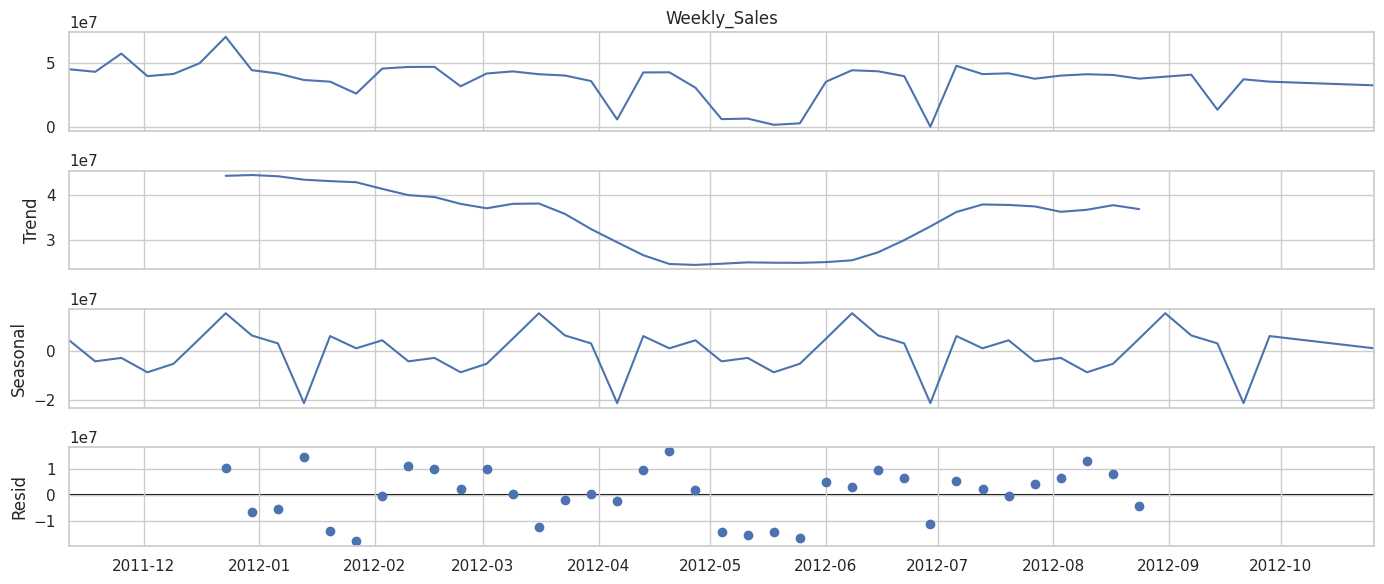

In [13]:
agg_sales = df.groupby('Date')['Weekly_Sales'].sum()
result = seasonal_decompose(agg_sales, model='additive', period=12)
result.plot()
plt.show()